# 02 · Cross-correlation gathers and convergence
Reference gathers (offset × lag), and how fast 10–120-min stacks converge to a leave-one-run-out reference for single pairs vs 1/2/5-km spatial stacks (`s06`–`s08b`).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from msdvv import load_config
cfg = load_config(); OUT = cfg['output_dir']; FIG = OUT + '/figs/'
pd.set_option('display.width', 200)

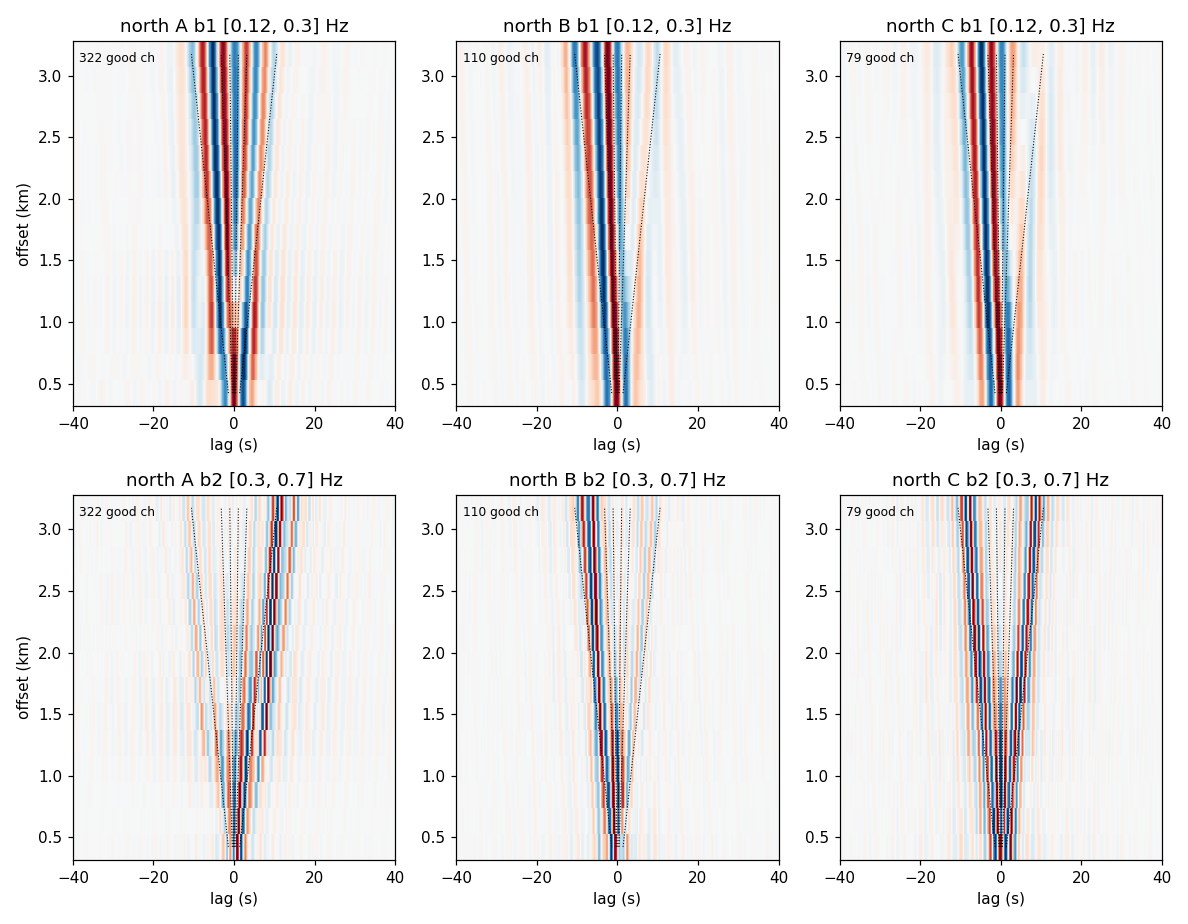

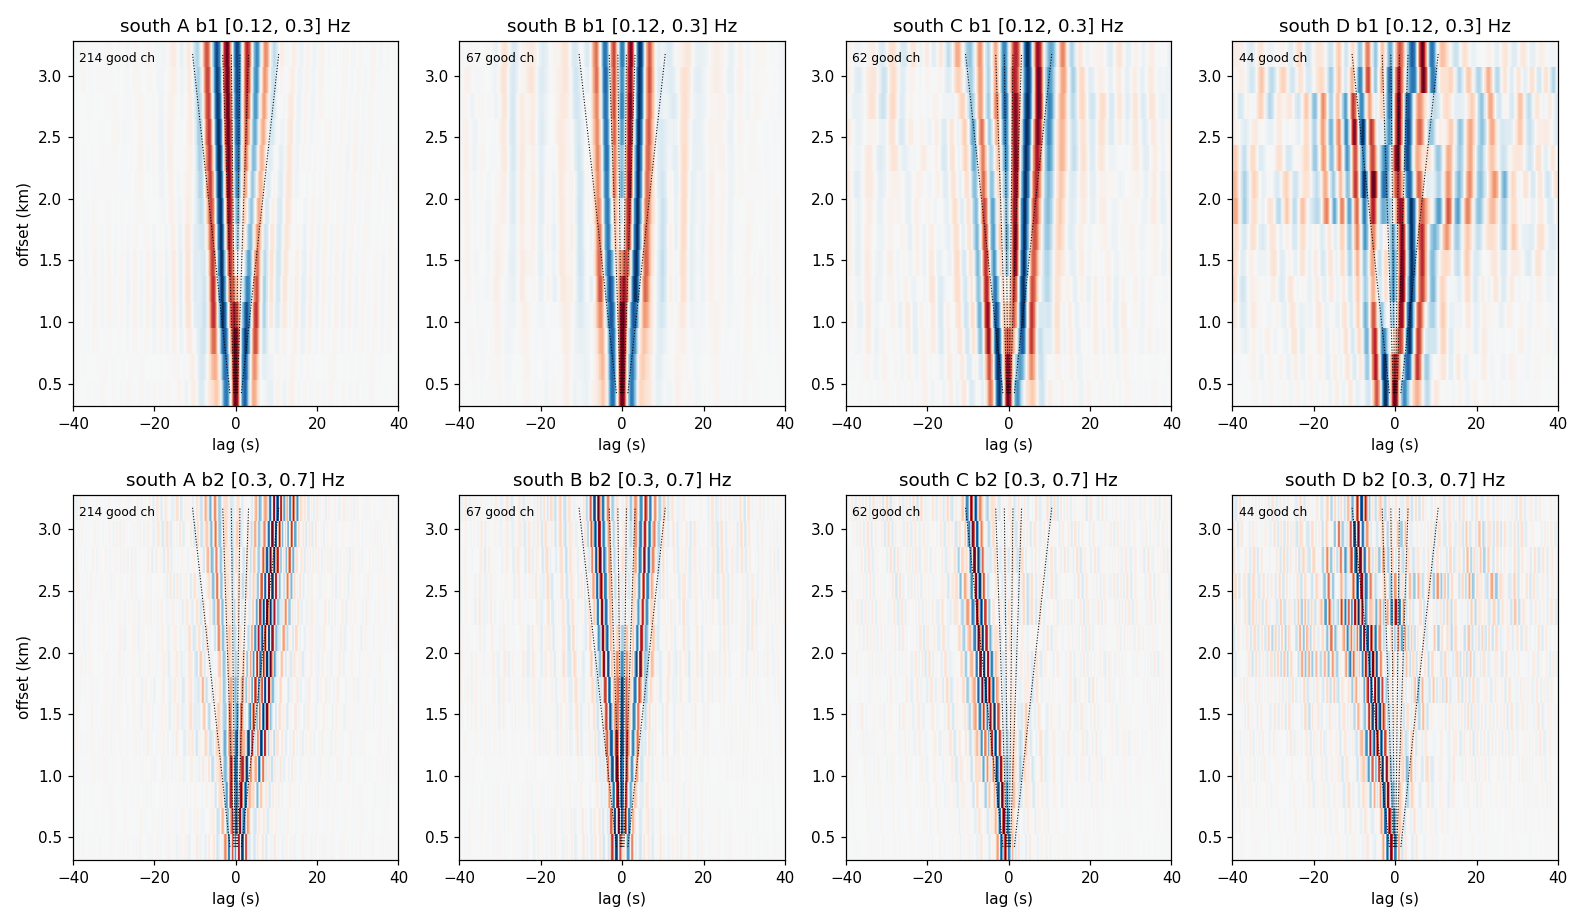

In [2]:
for c in ('north','south'): display(Image(f'{FIG}gathers_{c}_all.png'))

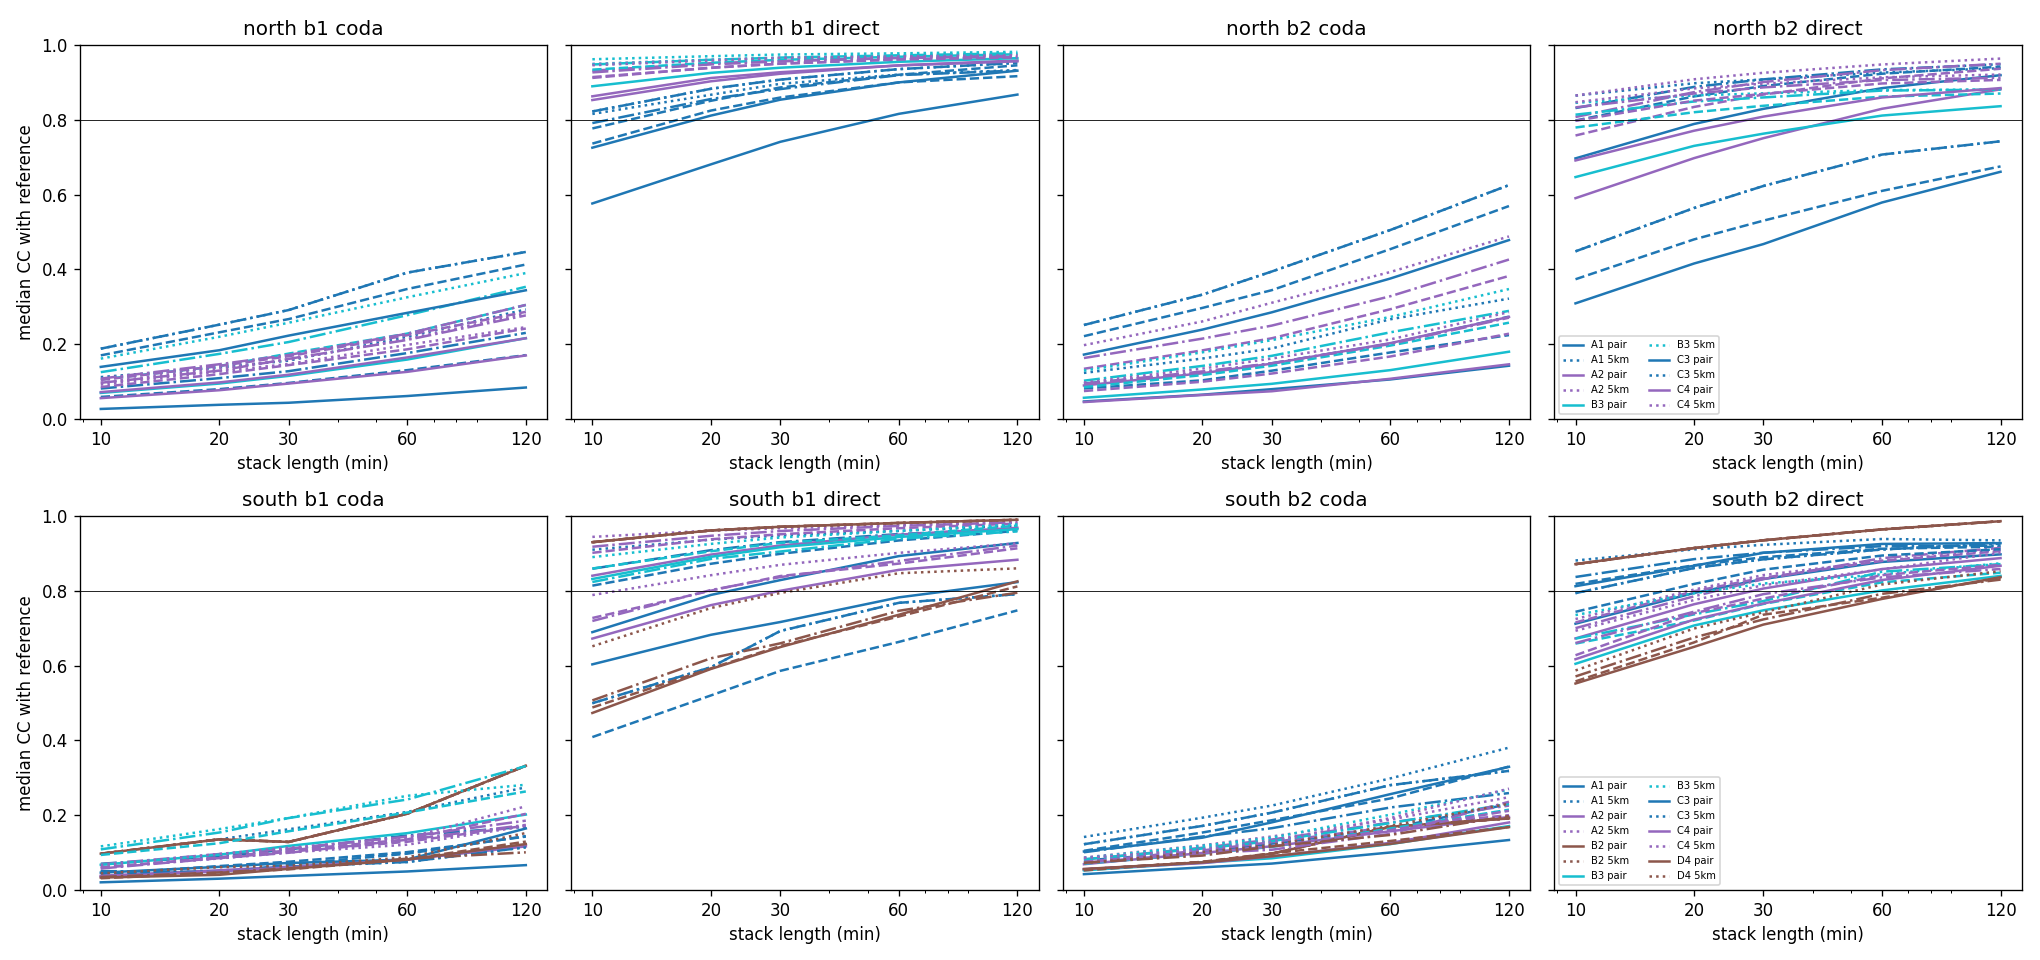

window                 coda                                           direct                                          
level                   1km         2km         5km        pair          1km         2km         5km        pair      
T_min                    30    60    30    60    30    60    30    60     30    60    30    60    30    60    30    60
cable block span band                                                                                                 
north A     1    b1    0.10  0.13  0.13  0.18  0.16  0.22  0.04  0.06   0.86  0.90  0.88  0.92  0.90  0.92  0.74  0.82
                 b2    0.13  0.18  0.15  0.20  0.19  0.27  0.08  0.11   0.89  0.92  0.91  0.93  0.91  0.93  0.83  0.88
            2    b1    0.14  0.19  0.16  0.21  0.15  0.20  0.09  0.13   0.95  0.96  0.96  0.97  0.97  0.97  0.92  0.95
                 b2    0.22  0.29  0.25  0.33  0.31  0.39  0.15  0.20   0.87  0.91  0.90  0.93  0.93  0.95  0.75  0.83
      B     3    b1    0.17  0.23  0.21  0.28  0.26  0.33  0.12  0.16   0.96  0.97  0.97  0.97  0.97  0.98  0.94  0.95
                 b2    0.14  0.20  0.17  0.23  0.21  0.27  0.09  0.13   0.84  0.86  0.86  0.88  0.87  0.88  0.76  0.81
      C     3    b1    0.27  0.35  0.29  0.39  0.29  0.39  0.22  0.28   0.89  0.92  0.91  0.94  0.91  0.94  0.85  0.90
                 b2    0.34  0.45  0.39  0.51  0.39  0.51  0.29  0.38   0.53  0.61  0.62  0.71  0.62  0.71  0.47  0.58
            4    b1    0.17  0.22  0.17  0.23  0.16  0.21  0.12  0.16   0.95  0.96  0.96  0.96  0.97  0.97  0.93  0.94
                 b2    0.12  0.17  0.15  0.20  0.16  0.21  0.07  0.11   0.87  0.90  0.89  0.91  0.90  0.91  0.81  0.86
south A     1    b1    0.08  0.10  0.11  0.15  0.16  0.21  0.04  0.05   0.90  0.93  0.93  0.95  0.95  0.96  0.83  0.89
                 b2    0.12  0.17  0.17  0.22  0.23  0.30  0.07  0.10   0.89  0.91  0.90  0.92  0.92  0.94  0.83  0.88
            2    b1    0.10  0.13  0.11  0.14  0.10  0.12  0.06  0.08   0.95  0.97  0.96  0.97  0.97  0.98  0.92  0.95
                 b2    0.13  0.17  0.14  0.18  0.14  0.19  0.12  0.16   0.83  0.88  0.83  0.89  0.84  0.88  0.81  0.86
      B     2    b1    0.13  0.20  0.13  0.20  0.13  0.20  0.13  0.20   0.97  0.98  0.97  0.98  0.97  0.98  0.97  0.98
                 b2    0.10  0.17  0.10  0.17  0.10  0.17  0.10  0.17   0.93  0.96  0.93  0.96  0.93  0.96  0.93  0.96
            3    b1    0.16  0.21  0.19  0.24  0.19  0.25  0.12  0.15   0.93  0.95  0.90  0.94  0.94  0.96  0.92  0.94
                 b2    0.12  0.16  0.13  0.18  0.14  0.20  0.08  0.12   0.76  0.82  0.77  0.85  0.82  0.84  0.75  0.80
      C     3    b1    0.07  0.10  0.06  0.07  0.06  0.07  0.07  0.08   0.59  0.66  0.69  0.77  0.69  0.77  0.72  0.78
                 b2    0.19  0.24  0.21  0.28  0.21  0.28  0.18  0.26   0.86  0.89  0.88  0.91  0.88  0.91  0.90  0.92
            4    b1    0.11  0.14  0.10  0.13  0.11  0.14  0.06  0.08   0.84  0.87  0.84  0.88  0.87  0.90  0.80  0.86
                 b2    0.12  0.16  0.11  0.15  0.13  0.19  0.09  0.13   0.78  0.84  0.79  0.84  0.81  0.86  0.77  0.83
      D     4    b1    0.06  0.08  0.06  0.08  0.06  0.09  0.06  0.08   0.65  0.73  0.66  0.75  0.79  0.85  0.65  0.74
                 b2    0.10  0.13  0.12  0.15  0.12  0.17  0.09  0.12   0.74  0.78  0.72  0.79  0.74  0.82  0.71  0.78

In [3]:
display(Image(FIG + 'convergence.png'))
s = pd.read_csv(OUT + '/convergence/summary.csv')
s[s.T_min.isin([30,60])].pivot_table(index=['cable','block','span','band'], columns=['window','level','T_min'], values='cc_median').round(2)

Late coda (≥15 s) does not converge within 2 h; direct and early-coda windows do. Tested remedies:

In [4]:
pd.read_csv(OUT + '/convergence/coda_fixes.csv').pivot_table(index=['cable','band'], columns='method', values='cc_median_60min').round(3)

method       base  early  kstack  kstack+svd   svd3
cable band                                         
north b1    0.245  0.902   0.128       0.206  0.356
      b2    0.302  0.837   0.166       0.224  0.440
south b1    0.162  0.802   0.109       0.143  0.193
      b2    0.189  0.651   0.099       0.108  0.218